# 2026 U.S. Midterm: topics, sentiment, prediction markets, and equities

In [1]:
# If this cell raises ModuleNotFoundError, install/select this project's kernel:
# !{sys.executable} -m pip install -r requirements.txt ipykernel
# !{sys.executable} -m ipykernel install --user --name fre-gy-7871a-a5 --display-name 'Python (FRE-GY Assignment 5)'
# Then use Jupyter: Kernel > Change Kernel > Python (FRE-GY Assignment 5).
# For twitterapi.io, create secrets/twitterapi_io.env; see secrets/README.md.

from pathlib import Path
import os
import sys, json, importlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path.cwd() / 'src'))
import midterm_pipeline
importlib.reload(midterm_pipeline)  # Load local edits even if this kernel was already running.
from midterm_pipeline import (load_project_secrets, credential_status, collect_text, discover_polymarket_sweep, choose_yes_token,
    polymarket_history, seed_topic_labels, sentiment_score, topic_daily_index,
    correlation_table, market_adjusted_returns, EQUITY_BASKET)

load_project_secrets()
print('Credential readiness (values hidden):', credential_status())
START, END = '2026-05-01', '2026-10-08'
pd.set_option('display.max_colwidth', 120)

Credential readiness (values hidden): {'twitterapi.io': True}


## 1. Collect text with provenance

GDELT, Google News RSS, Hacker News public search, Mastodon public tag timelines, and twitterapi.io X search are included in every collection run. `TWITTERAPI_IO_KEY` is required and is loaded from local secrets. The X integration calls read-only advanced search and caps retrieval at `TWITTERAPI_MAX_PAGES=3` by default because it is billed by returned post. The collection stores source and URL so sampling can be audited.

In [2]:
documents = collect_text(START, END)
assert not documents.empty, 'No text returned. Check network access, dates, or API credentials.'
print(f'{len(documents):,} unique documents')
source_counts = documents.groupby('source').size().rename('documents').to_frame()
display(source_counts)
print(f'Collected from {len(source_counts)} source(s). Add credentials if optional sources are absent.')
display(documents[['date', 'source', 'title', 'url']].head())

gdelt: 250 rows returned
google_news_rss: 100 rows returned


hacker_news: 100 rows returned


mastodon: 114 rows returned


twitterapi.io: 60 rows returned
Retained after date filtering/deduplication: {'gdelt': 250, 'google_news_rss': 99, 'hacker_news': 100, 'mastodon': 113, 'twitterapi.io': 60}
622 unique documents


,documents
source,
gdelt,250
google_news_rss,99
hacker_news,100
mastodon,113
twitterapi.io,60


Collected from 5 source(s). Add credentials if optional sources are absent.


,date,source,title,url
0,2026-08-10,gdelt,"Religion , immigration and abortion could shape key US Senate races , new polling suggests",https://www.christiantoday.com/news/religion-immigration-and-abortion-could-shape-key-us-senate-races-new-polling-su...
1,2026-09-09,gdelt,BGSU Poll : These are the issues topping voter minds right now,https://www.13abc.com/2026/09/09/bgsu-poll-these-are-issues-topping-voters-minds-right-now/
2,2026-08-05,gdelt,Trump Gets Worrying Midterm Warning Sign Across 3 New Polls,https://www.newsweek.com/donald-trump-midterm-warning-polls-12287511
3,2026-08-27,gdelt,Conservative group says one issue dwarfs all others in Senate races . It bad news for Trump | Voters First,https://www.unionleader.com/news/politics/voters/conservative-group-says-one-issue-dwarfs-all-others-in-senate-races...
4,2026-08-02,gdelt,Trump immigration agenda remains his biggest political strength : What the latest poll shows,https://www.livemint.com/news/us-news/trumps-immigration-agenda-remains-his-biggest-political-strength-what-the-late...


## 2. Discover and validate topics

BERTopic is preferred because news/social posts are short and semantically varied. If its optional transformer stack is unavailable, a transparent seed-label classifier is used. Either branch requires review of representative texts before labeling a topic as a voter priority.

In [3]:
import importlib.util
if importlib.util.find_spec('bertopic') is not None:
    from bertopic import BERTopic
    model = BERTopic(min_topic_size=max(10, len(documents)//100), verbose=False)
    labels, _ = model.fit_transform(documents['text'].tolist())
    documents['topic'] = pd.Series(labels, index=documents.index).map(lambda x: f'bertopic_{x}')
    display(model.get_topic_info().head(15))
    print('Review representative documents above; map BERTopic labels to substantive issue names before final reporting.')
else:
    print('BERTopic is not installed; using audited seed labels. This is a supported fallback, not an error.')
    documents['topic'] = seed_topic_labels(documents['text'])

display(documents['topic'].value_counts().rename_axis('topic').to_frame('documents'))

BERTopic is not installed; using audited seed labels. This is a supported fallback, not an error.


,documents
topic,
other,395
immigration,79
cost_of_living,55
foreign_policy_energy,43
democracy_rights,26
health_care,24


In [4]:
# Audit examples: read these before accepting a label or reporting salience.
for topic in documents['topic'].value_counts().head(6).index:
    print('\n###', topic)
    display(documents.loc[documents.topic.eq(topic), ['date', 'source', 'title', 'text']].head(3))


### other


,date,source,title,text
1,2026-09-09,gdelt,BGSU Poll : These are the issues topping voter minds right now,BGSU Poll : These are the issues topping voter minds right now. https://www.13abc.com/2026/09/09/bgsu-poll-these-are...
5,2026-09-20,gdelt,Poll Shows Trump Approval Rating Hits Low Ahead Of Midterms,Poll Shows Trump Approval Rating Hits Low Ahead Of Midterms. https://650keni.iheart.com/content/2026-09-20-poll-show...
6,2026-09-20,gdelt,Poll Shows Trump Approval Rating Hits Low Ahead Of Midterms,Poll Shows Trump Approval Rating Hits Low Ahead Of Midterms. https://790waeb.iheart.com/content/2026-09-20-poll-show...



### immigration


,date,source,title,text
0,2026-08-10,gdelt,"Religion , immigration and abortion could shape key US Senate races , new polling suggests","Religion , immigration and abortion could shape key US Senate races , new polling suggests. https://www.christiantod..."
4,2026-08-02,gdelt,Trump immigration agenda remains his biggest political strength : What the latest poll shows,Trump immigration agenda remains his biggest political strength : What the latest poll shows. https://www.livemint.c...
70,2026-09-22,gdelt,US Midterm Election 2026 | Hate Crime Threat Against Indians & Trump,US Midterm Election 2026 | Hate Crime Threat Against Indians & Trump. https://www.bhaskar.com/g/international/news/u...



### cost_of_living


...

,date,source,title,text
2,2026-08-05,gdelt,Trump Gets Worrying Midterm Warning Sign Across 3 New Polls,Trump Gets Worrying Midterm Warning Sign Across 3 New Polls. https://www.newsweek.com/donald-trump-midterm-warning-p...
3,2026-08-27,gdelt,Conservative group says one issue dwarfs all others in Senate races . It bad news for Trump | Voters First,Conservative group says one issue dwarfs all others in Senate races . It bad news for Trump | Voters First. https://...
68,2026-08-15,gdelt,Where Do Candidates Stand on Energy ? There Is No Issue More Important to Us All .,Where Do Candidates Stand on Energy ? There Is No Issue More Important to Us All . . https://wattsupwiththat.com/202...



### democracy_rights


,date,source,title,text
73,2026-08-26,gdelt,Abortion rights group endorses Democrat Troy Jackson in critical Maine Senate race,Abortion rights group endorses Democrat Troy Jackson in critical Maine Senate race. https://www.yahoo.com/news/polit...
132,2026-07-15,gdelt,Abortion not a focus in Texas race for U . S . Senate as neither candidates emphasize the issue,Abortion not a focus in Texas race for U . S . Senate as neither candidates emphasize the issue. https://www.ksat.co...
133,2026-07-15,gdelt,"Paxton , Talarico arent emphasizing abortion in the Senate race","Paxton , Talarico arent emphasizing abortion in the Senate race. https://www.texastribune.org/2026/07/15/texas-ken-p..."



### health_care


,date,source,title,text
112,2026-09-28,gdelt,Health Care and Everyday Expenses Dominate 2026 Midterm Concerns For Rural Voters : Poll,Health Care and Everyday Expenses Dominate 2026 Midterm Concerns For Rural Voters : Poll. https://www.ibtimes.com/he...
177,2026-08-19,gdelt,Tiffany Vote for 2025 Medicaid Cuts Could Be Issue in Race for Governor » Urban Milwaukee,Tiffany Vote for 2025 Medicaid Cuts Could Be Issue in Race for Governor » Urban Milwaukee. https://urbanmilwaukee.co...
270,2026-07-24,google_news_rss,Healthcare on the Ballot: The 2026 Midterm Elections - Pharmaceutical Executive,Healthcare on the Ballot: The 2026 Midterm Elections - Pharmaceutical Executive


## 3. Topic sentiment and salience

The baseline uses VADER compound sentiment. Replace with FinBERT after validating a held-out, manually labeled policy/campaign sample. The signed index is `mean sentiment × log(1 + mentions)`; raw sentiment and mention share remain visible.

,days,mentions,avg_sentiment,avg_salience
topic,,,,
other,67,395,-0.000967,0.759476
immigration,27,79,0.095555,0.343066
cost_of_living,21,55,0.001623,0.362615
foreign_policy_energy,14,43,-0.414997,0.329174
democracy_rights,16,26,0.190461,0.280210
health_care,12,24,-0.154671,0.262137


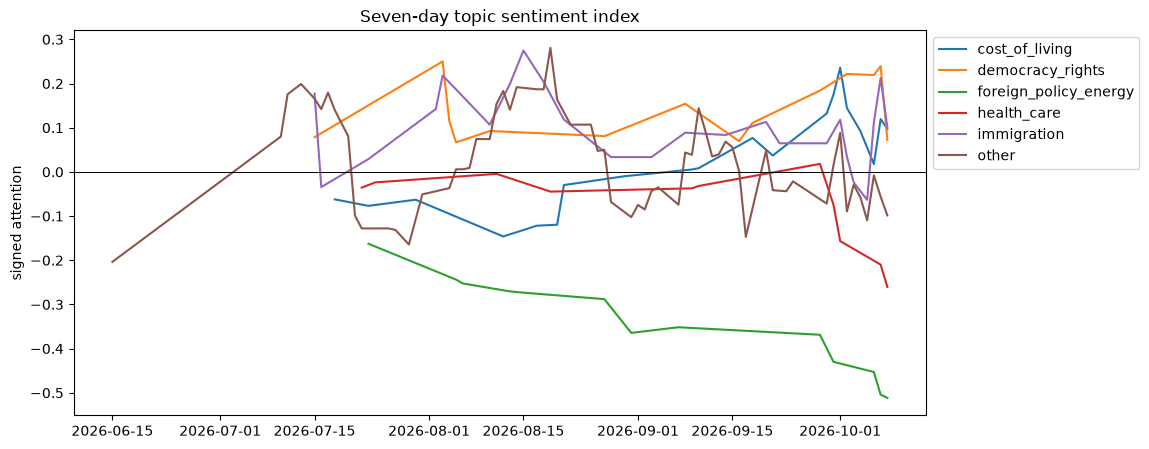

In [5]:
topic_index = topic_daily_index(documents)
summary = (topic_index.groupby('topic').agg(days=('date','nunique'), mentions=('mentions','sum'),
    avg_sentiment=('sentiment','mean'), avg_salience=('salience','mean')).sort_values('mentions', ascending=False))
display(summary)
fig, ax = plt.subplots(figsize=(11,5))
for topic, g in topic_index.groupby('topic'):
    ax.plot(g.date, g.sentiment_index.rolling(7, min_periods=2).mean(), label=topic)
ax.axhline(0, color='black', lw=.7); ax.legend(bbox_to_anchor=(1,1)); ax.set(title='Seven-day topic sentiment index', ylabel='signed attention')
Path('figures').mkdir(exist_ok=True); fig.savefig('figures/topic_sentiment_index.png', dpi=150, bbox_inches='tight')
plt.show()

## 4. Prediction-market probability of a Democratic sweep

A sweep is Democratic control of both House and Senate. Search contracts first. Select a direct sweep contract only if its wording exactly matches that definition; otherwise calculate a documented product from selected House and Senate contracts, noting the independence assumption. Do not automatically use the first result.

In [6]:
markets = discover_polymarket_sweep()
display(markets)
# Prefer a direct market whose literal YES outcome resolves to Democratic control of both chambers.
# If discovery is empty, set POLYMARKET_YES_TOKEN in secrets/twitterapi_io.env (or the shell) after inspecting a live contract.
yes_token = os.getenv('POLYMARKET_YES_TOKEN')
if markets.empty:
    print('No matching active Polymarket contract was found. This is not an error. Set POLYMARKET_YES_TOKEN for a verified current contract, or use a documented Kalshi alternative.')
elif yes_token:
    print('Using POLYMARKET_YES_TOKEN supplied through local secrets.')
else:
    SELECTED_ROW = 0  # Review question/liquidity above before retaining this choice.
    selected = markets.iloc[SELECTED_ROW]
    print('Selected contract:', selected['question'])
    yes_token = choose_yes_token(selected)

,id,question,slug,clobTokenIds,outcomes,outcomePrices,liquidityNum,volumeNum
0,562828,"2026 Balance of Power: D Senate, D House",2026-balance-of-power-d-senate-d-house-949,"[""34722410608062854697106861099776685947172185964394483545370684749662285977831"", ""244835632286600281210204307228967...","[""Yes"", ""No""]","[""0.625"", ""0.375""]",2.211260e+06,5.134885e+06


Using POLYMARKET_YES_TOKEN supplied through local secrets.


,date,sweep_probability
155,2026-10-04,0.645
156,2026-10-05,0.665
157,2026-10-06,0.655
158,2026-10-07,0.645
159,2026-10-08,0.635


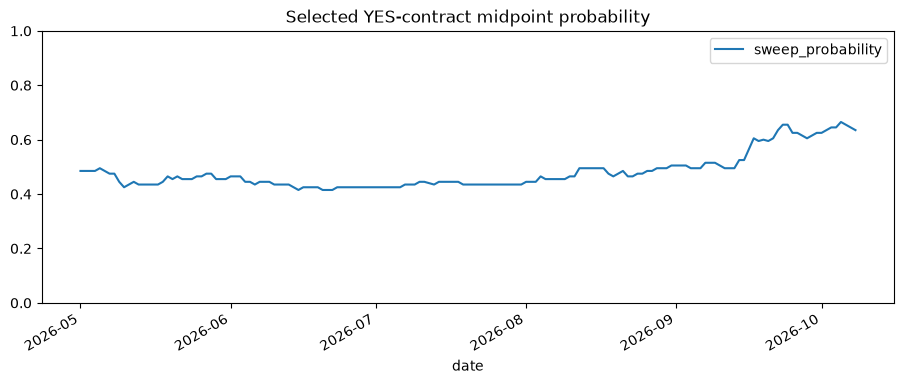

In [7]:
start_ts, end_ts = int(pd.Timestamp(START, tz='UTC').timestamp()), int(pd.Timestamp(END, tz='UTC').timestamp())
if yes_token:
    sweep = polymarket_history(yes_token, start_ts, end_ts)
    display(sweep.tail())
    ax = sweep.plot(x='date', y='sweep_probability', figsize=(11,4), title='Selected YES-contract midpoint probability'); plt.ylim(0,1)
    Path('figures').mkdir(exist_ok=True); ax.figure.savefig('figures/democratic_sweep_probability.png', dpi=150, bbox_inches='tight')
    plt.show()
else:
    sweep = pd.DataFrame(columns=['date', 'sweep_probability'])
    print('Market-correlation sections will safely report insufficient data until a verified YES token is supplied.')

## 5. Sentiment-market association

These are associations, not forecasts or causal estimates. Daily levels can trend together; report first-difference and lagged checks in a final write-up.

In [8]:
corr = correlation_table(topic_index, sweep, min_obs=20)
if corr.empty:
    print('Insufficient overlapping days: no correlation reported.')
else:
    display(corr.sort_values('pearson_r', key=lambda x: x.abs(), ascending=False))
    diff_index = topic_index.assign(sentiment_index=lambda x: x.groupby('topic').sentiment_index.diff())
    diff_sweep = sweep.assign(sweep_probability=lambda x: x.sweep_probability.diff())
    display(correlation_table(diff_index, diff_sweep, min_obs=20).rename(columns={'pearson_r':'diff_pearson_r'}))

,topic,n,pearson_r,spearman_r
0,cost_of_living,21,0.124155,0.064305
1,immigration,27,-0.101716,0.002498
2,other,66,-0.058840,-0.066483


,topic,n,diff_pearson_r,spearman_r
0,cost_of_living,20,-0.234760,-0.168704
1,immigration,26,0.073934,0.116123
2,other,65,-0.073973,-0.137937


## 6. Market-adjusted equity basket

Each name is a policy-exposure hypothesis, not a recommendation. Returns are adjusted by same-day SPY return. Use a factor model and pre-specified portfolio weights for a more demanding extension.

In [9]:
display(EQUITY_BASKET)
equity = market_adjusted_returns(EQUITY_BASKET.ticker, START, END)
equity = equity.merge(EQUITY_BASKET[['ticker','topic']], on='ticker')
panel = equity.merge(topic_index[['date','topic','sentiment_index']], on=['date','topic'], how='inner')
results = []
for ticker, g in panel.groupby('ticker'):
    results.append({'ticker': ticker, 'n': len(g), 'corr_same_day': g.market_adjusted_return.corr(g.sentiment_index),
                    'corr_sentiment_lag1': g.market_adjusted_return.corr(g.sentiment_index.shift(1))})
display(pd.DataFrame(results).merge(EQUITY_BASKET, on='ticker').sort_values('corr_sentiment_lag1', key=lambda x: x.abs(), ascending=False))

,ticker,name,topic,hypothesis
0,XLP,Consumer Staples Select Sector SPDR,cost_of_living,defensive consumption / real-income stress
1,WMT,Walmart,cost_of_living,value-trade-down exposure
2,UNH,UnitedHealth,health_care,health-policy / reimbursement sensitivity
3,CVS,CVS Health,health_care,drug-price and coverage policy sensitivity
4,GEO,GEO Group,immigration,immigration-detention policy sensitivity
5,CXW,CoreCivic,immigration,immigration-detention policy sensitivity
6,NEE,NextEra Energy,foreign_policy_energy,energy / climate-policy sensitivity
7,XLE,Energy Select Sector SPDR,foreign_policy_energy,energy-price and permitting sensitivity


,ticker,n,corr_same_day,corr_sentiment_lag1,name,topic,hypothesis
3,NEE,10,-0.175588,-0.636589,NextEra Energy,foreign_policy_energy,energy / climate-policy sensitivity
0,CVS,11,0.024011,-0.467601,CVS Health,health_care,drug-price and coverage policy sensitivity
4,UNH,11,0.364478,-0.360527,UnitedHealth,health_care,health-policy / reimbursement sensitivity
2,GEO,22,-0.259233,-0.181420,GEO Group,immigration,immigration-detention policy sensitivity
6,XLE,10,0.044207,-0.171806,Energy Select Sector SPDR,foreign_policy_energy,energy-price and permitting sensitivity
7,XLP,17,0.017385,-0.139610,Consumer Staples Select Sector SPDR,cost_of_living,defensive consumption / real-income stress
5,WMT,17,-0.116774,-0.124957,Walmart,cost_of_living,value-trade-down exposure
1,CXW,22,-0.249465,-0.120420,CoreCivic,immigration,immigration-detention policy sensitivity


## 7. Interpretation of this executed run

### Coverage and topic table

The final October 8 run retained **622 unique documents**: 250 GDELT (40.2%), 113 Mastodon (18.2%), 100 Hacker News (16.1%), 99 Google News RSS (15.9%), and 60 twitterapi.io posts (9.6%). GDELT initially returned HTTP 429 in an earlier refresh but was successfully collected after a rate-limit-compliant retry schedule. This is more diverse than a news-only sample, but it is not a representative voter survey: each source has different coverage, selection, and engagement incentives.

The seed-label table places 395 documents (63.5%) in `other`, so it should not be read as a complete map of voter concerns. Within the predefined issue set, immigration is the most frequent label (79 documents), followed by cost of living (55), foreign policy/energy (43), democracy/rights (26), and health care (24). This is salience in the collected text, not a population ranking of voter priorities. BERTopic was unavailable in this run, so these labels come from the transparent seed fallback and should be validated against representative documents.

### Figure: seven-day topic sentiment index

The plot is a volume-aware, signed attention index rather than a poll. Foreign policy/energy has the most negative average baseline sentiment (-0.415); health care (-0.155) is also negative; cost of living is essentially neutral (+0.002); immigration (+0.096) and democracy/rights (+0.190) are positive. Sparse topic coverage (12-27 days for the predefined topics) means apparent spikes are sensitive to a small number of documents and should not be overinterpreted.

### Figure: Democratic-sweep probability

The selected Polymarket contract is `2026 Balance of Power: D Senate, D House`. Its YES midpoint finishes at **63.5%** on October 8, after 64.5%, 66.5%, 65.5%, and 64.5% over October 4-7. The figure shows a market-implied contract price, not a calibrated forecast or a polling average.

### Sentiment-market table

Cost of living, immigration, and the broad `other` bucket meet the 20-overlap-day reporting threshold in this successful refresh. Their level associations with sweep probability are all small: cost of living is +0.124 (n=21), immigration is -0.102 (n=27), and `other` is -0.059 (n=66). On first differences, cost of living is moderately negative (-0.235) while immigration is modestly positive (+0.074). `Other` is not an interpretable voter issue. These relationships are neither causal nor statistically decisive; the short samples make them a prompt for robustness checks, not a trading or election signal.

### Equity table

The equity diagnostics are especially exploratory because each ticker has only 10-22 aligned observations. UNH is positive on the same day (+0.364) while CVS is near zero (+0.024); immigration-linked GEO and CXW are both negative on the same day (-0.259 and -0.249). The largest one-day-lag magnitude is NEE at -0.637, but it has only ten observations. The mixed signs and short windows do not support a portfolio-level conclusion; they show that name-specific news and ordinary market factors likely dominate any common election-sentiment effect.
